# Variant level analysis

This notebook maps each guide to the protein changes it is predicted to install,
carries the guide z-scores onto those variants, and plots them.


## Setup


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from adjustText import adjust_text
from matplotlib.lines import Line2D
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
import src
from src import (
    CELL_LINE_COLOUR,
    DIAGONAL,
    ORIGIN,
    PATHWAY_COLOUR,
    axis_ticks,
    save_plot,
    ticked_axis,
    square_axes,
)

STUDY = C.THIS_STUDY
FDR = 0.05

## Guide to amino acid variant

A guide is kept where VEP reports an amino acid substitution: missense, nonsense and
start-lost edits. The variant is named in one letter code, for example `E545K`.

One guide can install more than one substitution. Those guides are kept and contribute
to every variant they make, which is recorded in `n_guides`; set `SINGLE_EDIT_ONLY` to
restrict the table to guides that change exactly one residue, where attribution is
unambiguous.


In [2]:
SINGLE_EDIT_ONLY = False

annotation = pd.read_csv(
    C.dataset_file(STUDY, "annotation"),
    low_memory=False,
    usecols=[
        "guide",
        "gene",
        "vep_Protein_position",
        "vep_Amino_acids",
        "vep_Consequence",
    ],
)

changes = annotation[annotation.vep_Amino_acids.astype(str).str.contains("/", na=False)]
split = changes.vep_Amino_acids.str.split("/", n=1, expand=True)
reference, alternate = split[0], split[1]
position = pd.to_numeric(
    changes.vep_Protein_position.astype(str).str.split("-").str[0], errors="coerce"
)

variants = changes.assign(
    residue=position.astype("Int64"),
    aa_variant=reference + position.astype("Int64").astype(str) + alternate,
    pathway=changes.gene.map(C.GENE_PATHWAY),
)[["guide", "gene", "pathway", "residue", "aa_variant", "vep_Consequence"]]

edits_per_guide = variants.groupby("guide").aa_variant.nunique()
if SINGLE_EDIT_ONLY:
    variants = variants[variants.guide.isin(edits_per_guide[edits_per_guide == 1].index)]

variants = variants.drop_duplicates(["guide", "gene", "aa_variant"])

# Two variants installed by exactly the same guides cannot be told apart by the screen,
# so they carry the same score and are labelled together.
support = (
    variants.groupby(["gene", "aa_variant"], as_index=False)
    .guide.agg(lambda names: "|".join(sorted(names)))
    .rename(columns={"guide": "support"})
)
variants = variants.merge(support, on=["gene", "aa_variant"])

print(f"{len(variants):,} guide to variant pairs")
print(f"{variants.aa_variant.nunique():,} distinct variants over {variants.gene.nunique()} genes")
print(f"substitutions per guide: {edits_per_guide.value_counts().sort_index().to_dict()}")
print(f"genes with no pathway assigned: {sorted(variants.loc[variants.pathway.isna(), 'gene'].unique())}")

28,241 guide to variant pairs
13,015 distinct variants over 30 genes
substitutions per guide: {1: 14664, 2: 5368, 3: 843, 4: 78}
genes with no pathway assigned: []


## Variant level scores

The collapsed z-score of every guide making a variant is averaged, giving one value per
variant and condition. `n_guides` says how many guides that average rests on.

Significance is discrete: a variant is called when at least one of its sgRNAs is called
at FDR < 5%.


In [3]:
hits = pd.read_csv(C.dataset_file(STUDY, "hits"))

scored = hits.merge(variants, on="guide")
variant_scores = (
    scored.groupby(["condition", "gene", "pathway", "aa_variant", "residue", "support"])
    .agg(
        zscore=("zscore", "mean"),
        n_guides=("guide", "nunique"),
        n_resistance=("call", lambda calls: (calls == "resistance").sum()),
        n_sensitivity=("call", lambda calls: (calls == "sensitivity").sum()),
    )
    .reset_index()
)

# A variant is called when at least one of its sgRNAs is called, which is a discrete
# rule. The smallest FDR among those sgRNAs is not a variant level FDR and is not kept.
variant_scores["significant"] = (
    variant_scores.n_resistance + variant_scores.n_sensitivity
) > 0
variant_scores["direction"] = np.select(
    [
        (variant_scores.n_resistance > 0) & (variant_scores.n_sensitivity > 0),
        variant_scores.n_resistance > 0,
        variant_scores.n_sensitivity > 0,
    ],
    ["conflicting", "resistance", "sensitivity"],
    default="neutral",
)
print(variant_scores.direction.value_counts().to_dict())

print(f"{len(variant_scores):,} variant by condition rows")
print(f"guides per variant: median {variant_scores.n_guides.median():.0f}, "
      f"max {variant_scores.n_guides.max()}")
variant_scores.head()

{'neutral': 215400, 'sensitivity': 9276, 'resistance': 4868, 'conflicting': 42}
229,586 variant by condition rows
guides per variant: median 2, max 5


,condition,gene,pathway,aa_variant,residue,support,zscore,n_guides,n_resistance,n_sensitivity,significant,direction
0,A375_DO_vs_plasmid,AKT1,mTOR / PI3K\npathway,A102V,102,ACAACCGCCATCCAGACTGT|ACCGCCATCCAGACTGTGGC,0.357677,2,0,0,False,neutral
1,A375_DO_vs_plasmid,AKT1,mTOR / PI3K\npathway,A107T,107,CCGTCAGCCACAGTCTGGAT|GTCAGCCACAGTCTGGATGG|TCAG...,-0.022018,3,0,0,False,neutral
2,A375_DO_vs_plasmid,AKT1,mTOR / PI3K\npathway,A107V,107,TGTGGCTGACGGCCTCAAGA,0.219891,1,0,0,False,neutral
3,A375_DO_vs_plasmid,AKT1,mTOR / PI3K\npathway,A131T,131,CAGCCCCTGAGTTGTCACTG|TCAGCCCCTGAGTTGTCACT|TTCA...,-0.031520,3,0,0,False,neutral
4,A375_DO_vs_plasmid,AKT1,mTOR / PI3K\npathway,A131V,131,AGGGGCTGAAGAGATGGAGG|TCAGGGGCTGAAGAGATGGA,0.468245,2,0,0,False,neutral


A wide table with one column per cell line makes the cell line comparisons direct.


In [4]:
def wide(arm, reference="untreated", value="zscore"):
    """One row per variant, one column per cell line, for a single drug."""
    wanted = {
        cell_line: f"{cell_line}_{arm}_vs_{reference}" for cell_line in C.CELL_LINES
    }
    block = variant_scores[variant_scores.condition.isin(wanted.values())]
    table = block.pivot_table(
        index=["gene", "pathway", "aa_variant", "residue", "support"],
        columns="condition",
        values=value,
    ).reset_index()
    return table.rename(columns={v: k for k, v in wanted.items()}).dropna(
        subset=list(C.CELL_LINES)
    )


by_drug = {arm: wide(arm) for arm in C.DRUG_ARMS}
for arm, table in by_drug.items():
    print(f"{C.ARM_LABEL[arm]:12s} {len(table):,} variants scored in both cell lines")

Linsitinib   16,399 variants scored in both cell lines
Pictilisib   16,399 variants scored in both cell lines
SCH772984    16,399 variants scored in both cell lines


## A375 against HT-29, per drug


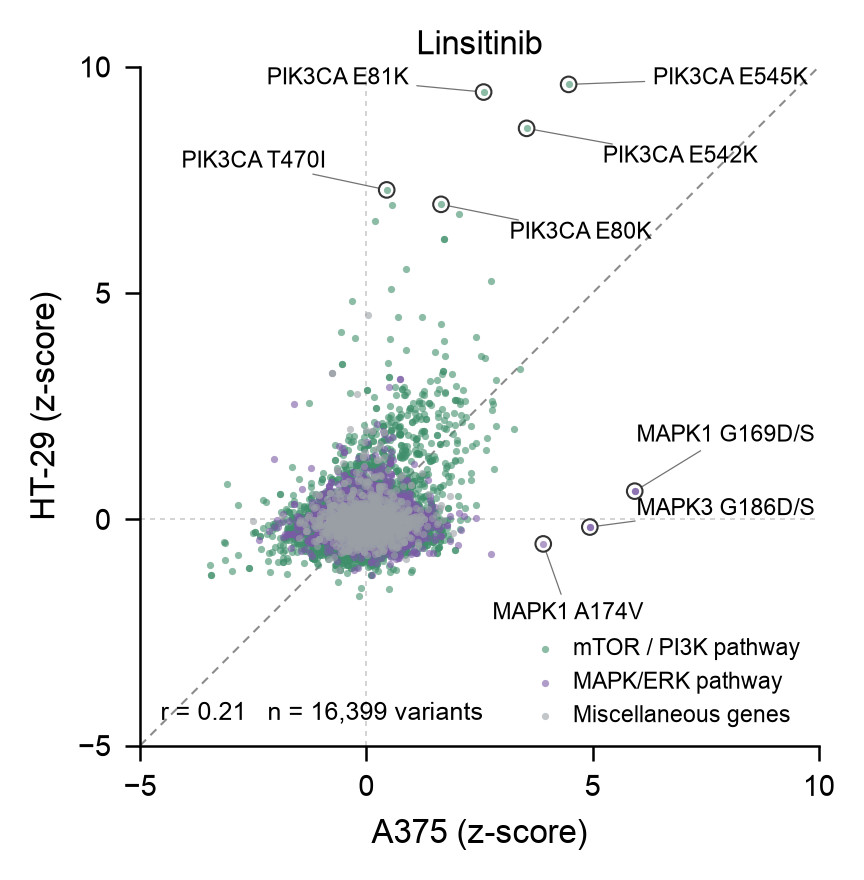

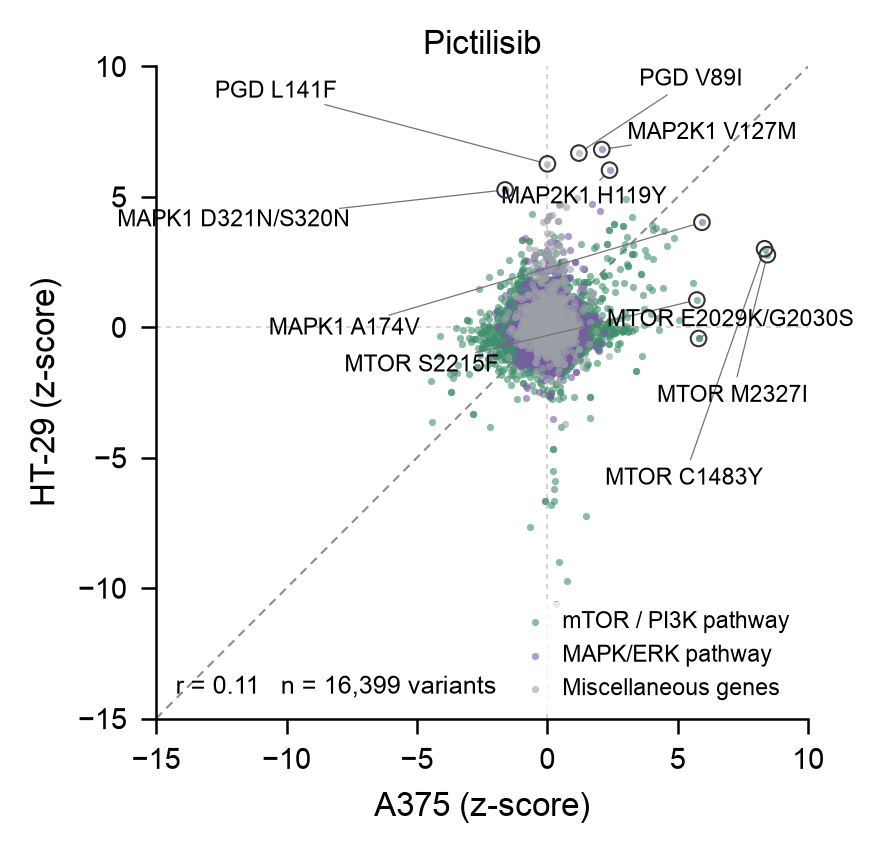

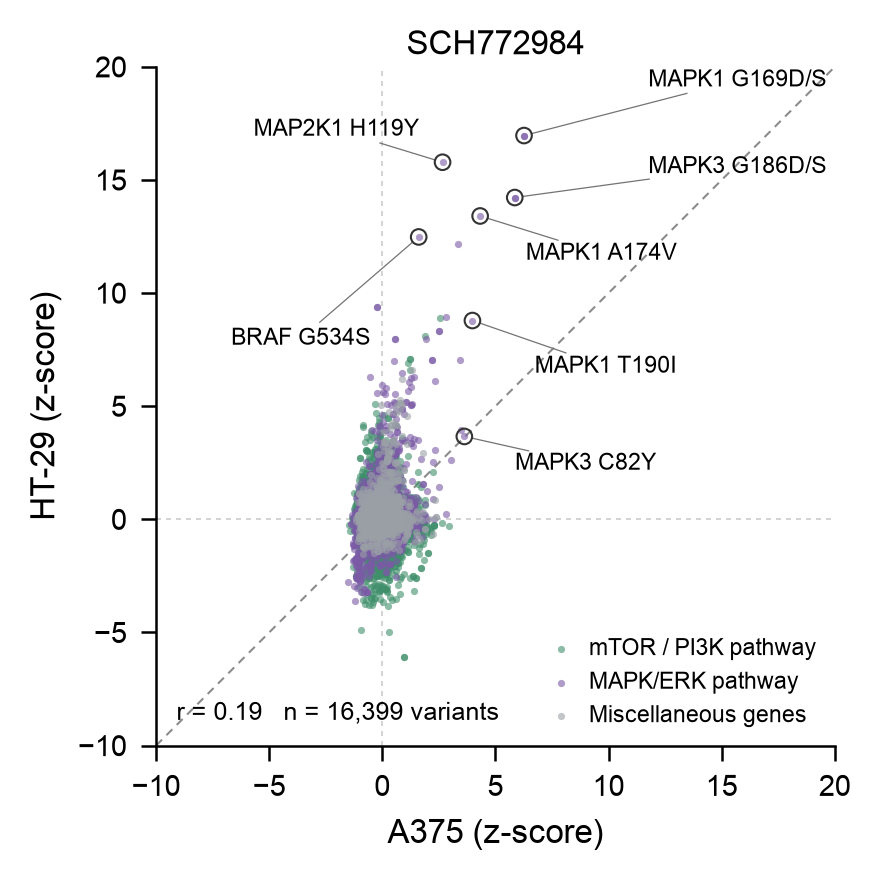

In [5]:
def merged_label(names):
    """G169S and G169D become G169S/D when only the new residue differs."""
    unique = sorted(set(names))
    if len(unique) == 1:
        return unique[0]
    stems = {name[:-1] for name in unique}
    if len(stems) == 1:
        return stems.pop() + "/".join(name[-1] for name in unique)
    return "/".join(unique)


def label_extremes(ax, table, count=5):
    """Name the most resistant variants on each axis, merging indistinguishable ones."""
    grouped = table.groupby(["gene", "support"], as_index=False).agg(
        **{line: (line, "first") for line in C.CELL_LINES},
        label=("aa_variant", merged_label),
    )
    chosen = pd.concat(
        [grouped.nlargest(count, line) for line in C.CELL_LINES]
    ).drop_duplicates(["gene", "support"])
    ax.scatter(
        chosen[C.CELL_LINES[0]],
        chosen[C.CELL_LINES[1]],
        s=14,
        facecolors="none",
        edgecolors="0.2",
        linewidths=0.5,
        zorder=5,
    )
    texts = [
        ax.text(
            getattr(row, C.CELL_LINES[0]),
            getattr(row, C.CELL_LINES[1]),
            f"{row.gene} {row.label}",
            fontsize=5.5,
        )
        for row in chosen.itertuples()
    ]
    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(arrowstyle="-", color="0.45", lw=0.3),
        expand=(2.0, 2.4),
        force_text=(0.8, 1.0),
        max_move=40,
        ensure_inside_axes=True,
    )
    return chosen


def cell_line_scatter(arm):
    table = by_drug[arm]
    fig, ax = plt.subplots(figsize=(2.8, 2.8))

    for pathway, colour in PATHWAY_COLOUR.items():
        block = table[table.pathway == pathway]
        ax.scatter(
            block[C.CELL_LINES[0]],
            block[C.CELL_LINES[1]],
            s=3,
            linewidths=0,
            alpha=0.6,
            color=colour,
            label=pathway.replace("\n", " "),
            rasterized=True,
        )

    ticks = square_axes(ax, table[C.CELL_LINES].to_numpy())
    ax.plot([ticks[0], ticks[-1]], [ticks[0], ticks[-1]], **DIAGONAL)
    ax.axhline(0, **ORIGIN)
    ax.axvline(0, **ORIGIN)
    ax.set_xlabel(f"{C.CELL_LINE_LABEL[C.CELL_LINES[0]]} (z-score)")
    ax.set_ylabel(f"{C.CELL_LINE_LABEL[C.CELL_LINES[1]]} (z-score)")
    ax.set_title(C.ARM_LABEL[arm], fontsize=8, pad=3)

    r = stats.pearsonr(table[C.CELL_LINES[0]], table[C.CELL_LINES[1]])[0]
    ax.annotate(
        f"r = {r:.2f}   n = {len(table):,} variants",
        xy=(0.03, 0.03),
        xycoords="axes fraction",
        ha="left",
        va="bottom",
        fontsize=6,
    )
    labelled = label_extremes(ax, table)
    ax.legend(
        loc="lower right",
        frameon=True,
        framealpha=0.75,
        facecolor="white",
        edgecolor="none",
        fontsize=5.5,
        handletextpad=0.2,
        borderaxespad=0.4,
    )

    fig.tight_layout(pad=0.3)
    save_plot(fig, f"variant_cell_lines_{arm}")
    plt.show()
    return labelled


top_variants = {arm: cell_line_scatter(arm) for arm in C.DRUG_ARMS}

In [6]:
pd.concat(
    [table.assign(drug=C.ARM_LABEL[arm]) for arm, table in top_variants.items()]
)[["drug", "gene", "label"] + list(C.CELL_LINES)].round(2).to_string(index=False)

'      drug   gene         label  A375  HT29\nLinsitinib  MAPK1       G169D/S  5.93  0.62\nLinsitinib  MAPK3       G186D/S  4.94 -0.17\nLinsitinib PIK3CA         E545K  4.47  9.61\nLinsitinib  MAPK1         A174V  3.91 -0.54\nLinsitinib PIK3CA         E542K  3.54  8.64\nLinsitinib PIK3CA          E81K  2.59  9.44\nLinsitinib PIK3CA         T470I  0.45  7.28\nLinsitinib PIK3CA          E80K  1.65  6.96\nPictilisib   MTOR        M2327I  8.44  2.78\nPictilisib   MTOR        C1483Y  8.32  3.01\nPictilisib  MAPK1         A174V  5.93  4.02\nPictilisib   MTOR E2029K/G2030S  5.80 -0.43\nPictilisib   MTOR        S2215F  5.73  1.05\nPictilisib MAP2K1         V127M  2.09  6.82\nPictilisib    PGD          V89I  1.21  6.68\nPictilisib    PGD         L141F  0.00  6.26\nPictilisib MAP2K1         H119Y  2.38  6.02\nPictilisib  MAPK1   D321N/S320N -1.62  5.27\n SCH772984  MAPK1       G169D/S  6.26 16.96\n SCH772984  MAPK3       G186D/S  5.85 14.22\n SCH772984  MAPK1         A174V  4.32 13.41\n SCH77298

## Variant effect along the protein


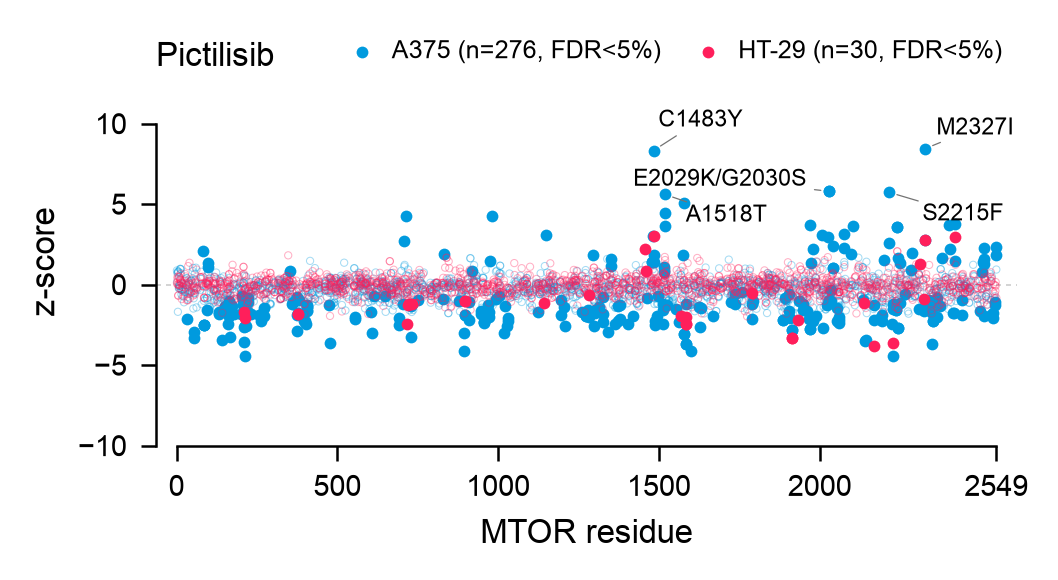

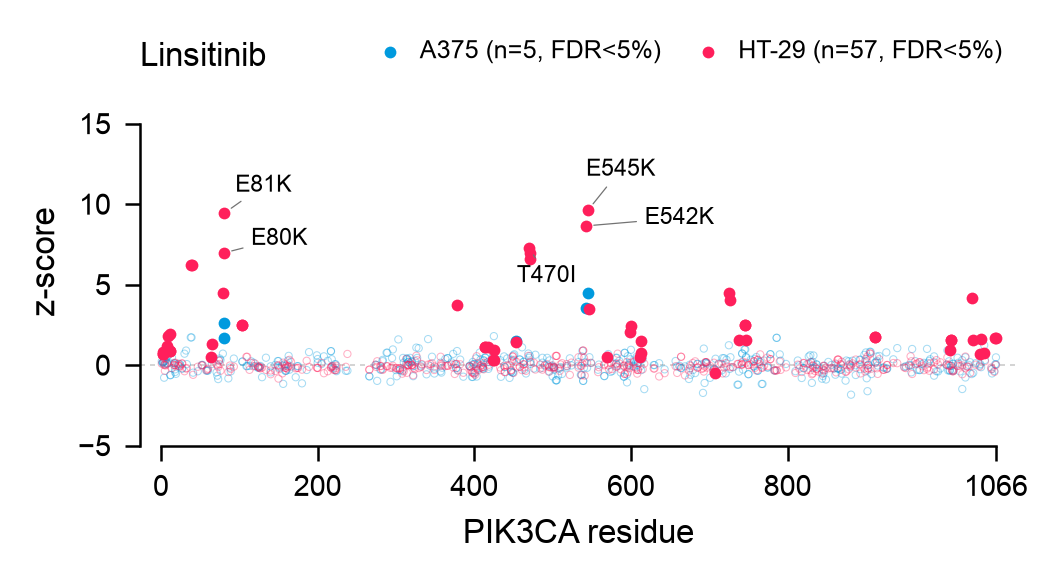

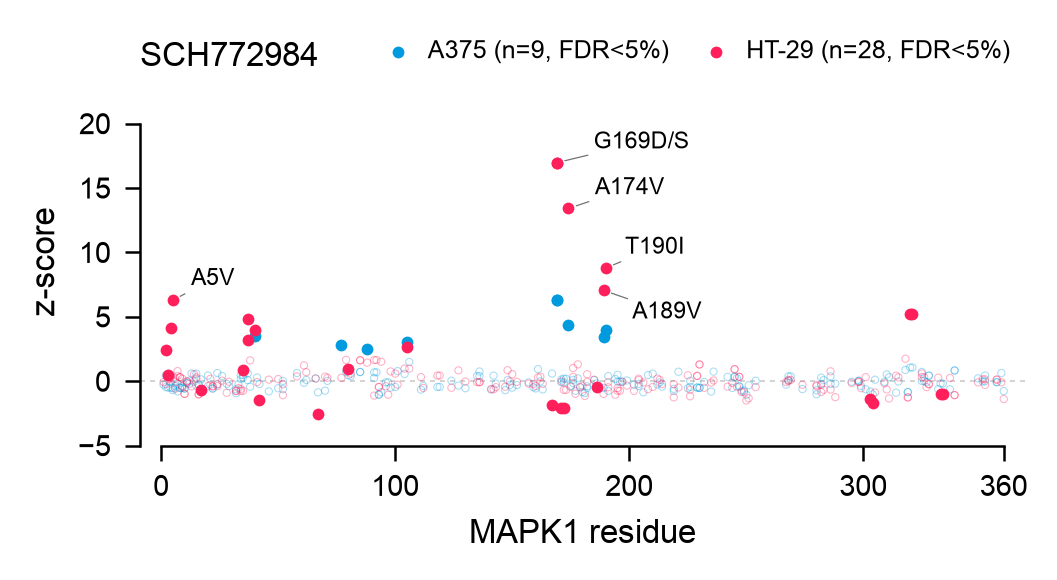

In [7]:
def position_plot(arm, gene, reference="untreated", filename=None):
    """z-score against residue position for one gene under one arm."""
    fig, ax = plt.subplots(figsize=(3.4, 1.8))

    blocks = []
    for cell_line in C.CELL_LINES:
        condition = f"{cell_line}_{arm}_vs_{reference}"
        block = variant_scores[
            (variant_scores.condition == condition) & (variant_scores.gene == gene)
        ]
        blocks.append(block)
        colour = CELL_LINE_COLOUR[cell_line]
        significant = block.significant
        ax.scatter(
            block.loc[~significant, "residue"],
            block.loc[~significant, "zscore"],
            s=3, linewidths=0.25, facecolors="none", edgecolors=colour, alpha=0.35,
        )
        ax.scatter(
            block.loc[significant, "residue"],
            block.loc[significant, "zscore"],
            s=8, linewidths=0, color=colour,
            label=f"{C.CELL_LINE_LABEL[cell_line]} (n={int(significant.sum())}, FDR<{FDR:.0%})",
        )

    last_residue = int(max(block.residue.max() for block in blocks))
    rounded = axis_ticks(0, last_residue, count=6)
    # keep the round ticks, then close the axis on the last residue itself, dropping
    # any round tick too near it to collide
    keep = [t for t in rounded if t <= last_residue * 0.92]
    ax.set_xticks([*keep, last_residue])
    margin = 0.025 * last_residue
    ax.set_xlim(-margin, last_residue + margin)
    ticked_axis(ax, "y", *ax.get_ylim())
    # headroom so the labels on the highest points stay inside the panel
    low, high = ax.get_ylim()
    ax.set_ylim(low, high + 0.14 * (high - low))

    highest = (
        pd.concat(blocks)
        .groupby("support", as_index=False)
        .agg(
            residue=("residue", "first"),
            zscore=("zscore", "max"),
            label=("aa_variant", merged_label),
        )
        .nlargest(5, "zscore")
    )
    # a label near the right edge is anchored on its right, so it grows inwards
    labels = [
        ax.text(
            row.residue,
            row.zscore,
            row.label,
            fontsize=5.5,
            ha="right" if row.residue > 0.6 * last_residue else "left",
        )
        for row in highest.itertuples()
    ]
    adjust_text(
        labels,
        ax=ax,
        arrowprops=dict(arrowstyle="-", color="0.45", lw=0.3),
        expand=(1.8, 2.2),
        ensure_inside_axes=True,
    )

    ax.axhline(0, **ORIGIN)
    ax.set_xlabel(f"{gene} residue")
    ax.set_ylabel("z-score")
    ax.set_title(C.ARM_LABEL[arm], fontsize=8, pad=3, loc="left")
    ax.legend(
        loc="lower right",
        bbox_to_anchor=(1.0, 1.0),
        ncols=2,
        frameon=False,
        fontsize=6,
        handletextpad=0.2,
        columnspacing=0.9,
        borderaxespad=0.2,
    )

    fig.tight_layout(pad=0.3)
    save_plot(fig, filename or f"variant_position_{arm}_{gene}")
    plt.show()


for arm, gene in [("PIC", "MTOR"), ("LIN", "PIK3CA"), ("SCH", "MAPK1")]:
    position_plot(arm, gene)

The same for the remaining pairs. The dropout panel uses the untreated arm against the
plasmid pool, so it shows which residues matter for fitness without any drug.


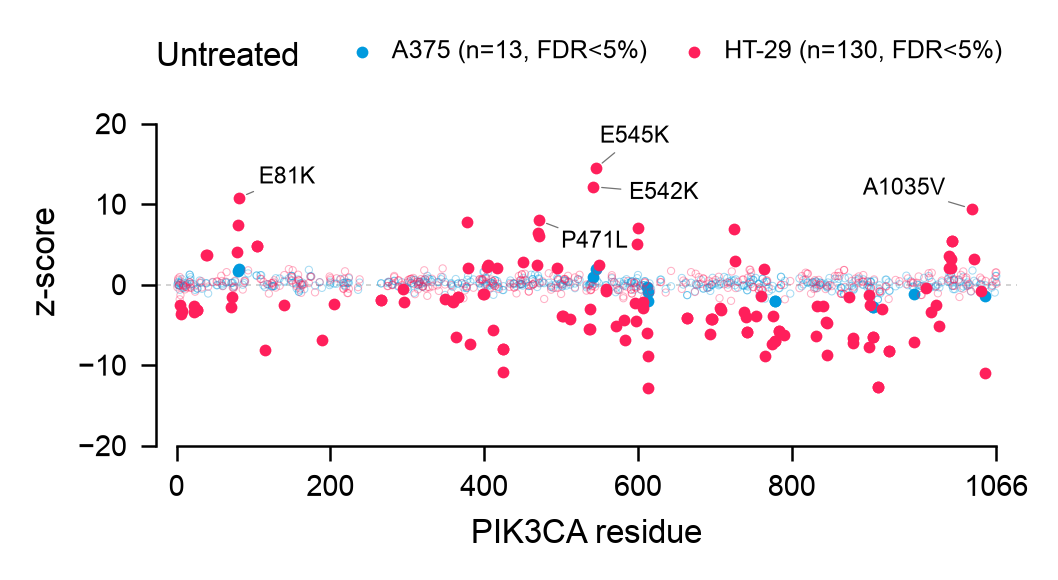

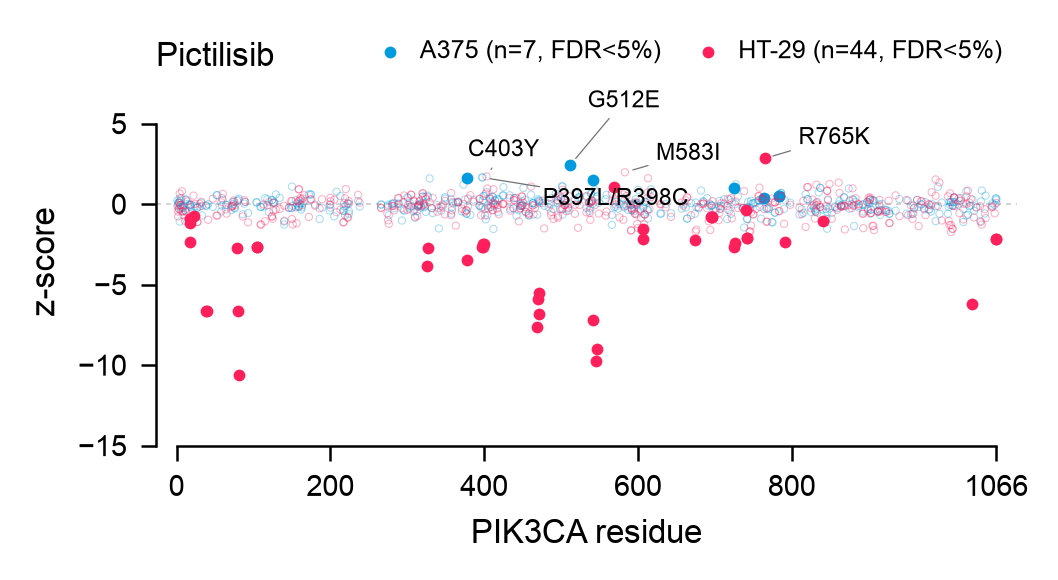

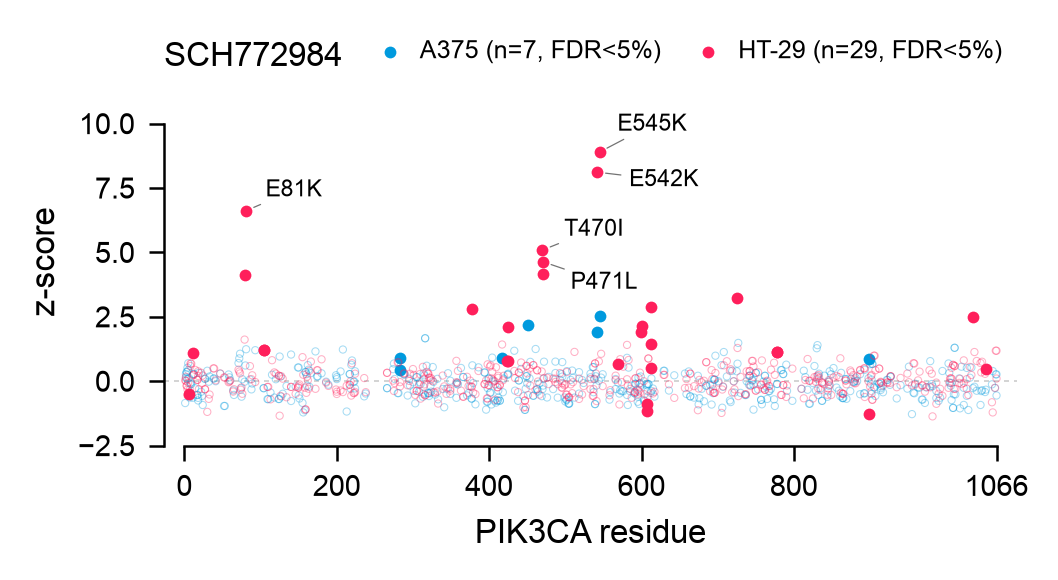

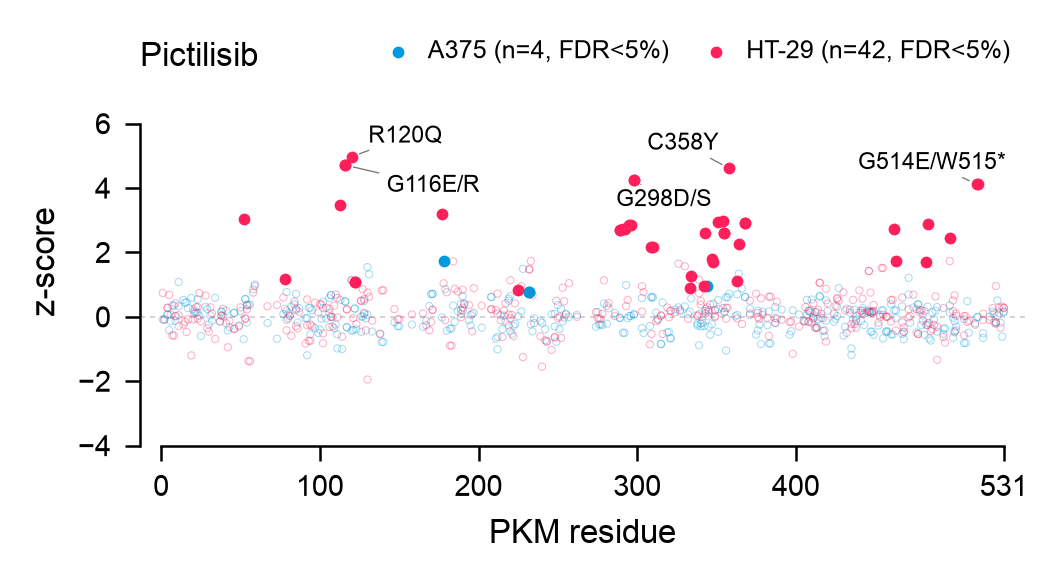

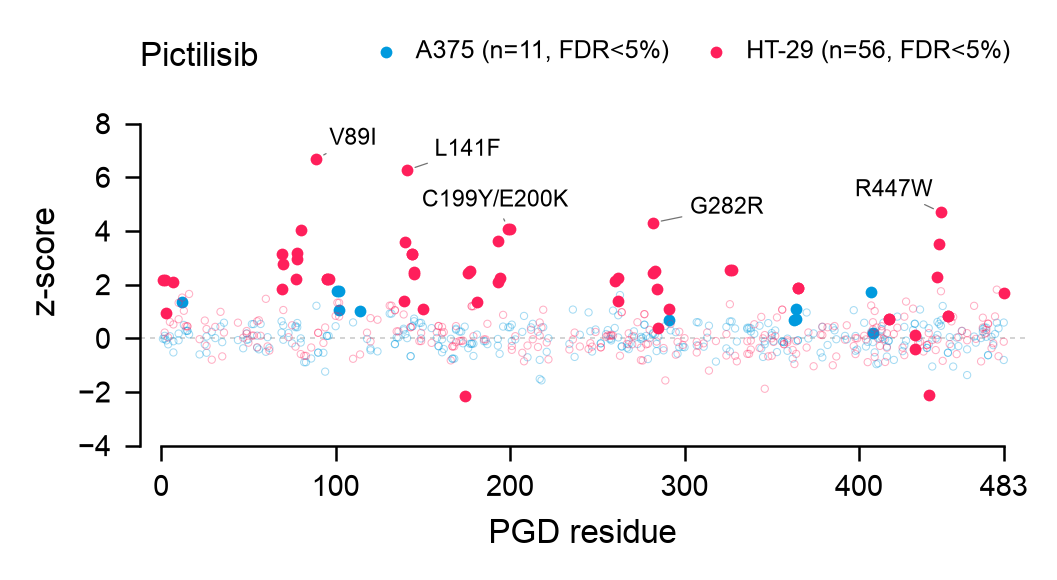

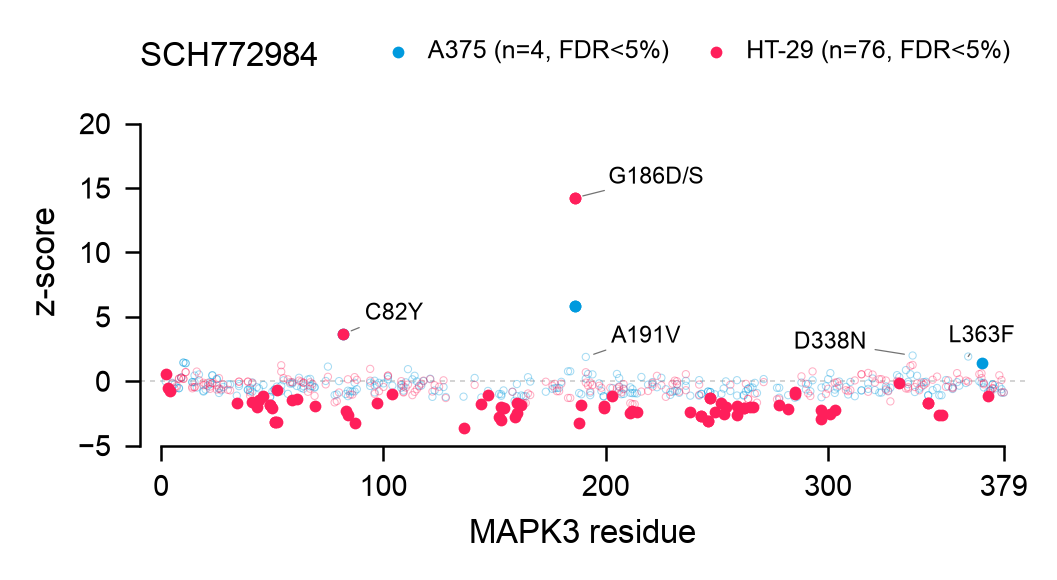

In [8]:
for arm, gene, reference in [
    ("DO", "PIK3CA", "plasmid"),
    ("PIC", "PIK3CA", "untreated"),
    ("SCH", "PIK3CA", "untreated"),
    ("PIC", "PKM", "untreated"),
    ("PIC", "PGD", "untreated"),
    ("SCH", "MAPK3", "untreated"),
]:
    position_plot(arm, gene, reference=reference)

## Replicate agreement at the variant level


In [9]:
zscores = pd.read_csv(C.dataset_file(STUDY, "zscores"), index_col=0)

replicate_columns = {
    (cell_line, arm, replicate): f"{cell_line}_{arm}_Rep{replicate}_vs_DO"
    for cell_line in C.CELL_LINES
    for arm in C.DRUG_ARMS
    for replicate in ("A", "B")
}
guide_level = zscores[list(replicate_columns.values())].rename_axis("guide").reset_index()
variant_replicates = (
    variants[["guide", "gene", "aa_variant"]]
    .merge(guide_level, on="guide")
    .groupby(["gene", "aa_variant"])
    .mean(numeric_only=True)
)
print(f"{len(variant_replicates):,} variants with replicate level scores")
variant_replicates.head()

16,399 variants with replicate level scores


A375_LIN_RepA_vs_DO  A375_LIN_RepB_vs_DO  \
gene aa_variant                                             
AKT1 A102V                  0.257742             1.051777   
     A107T                 -1.357469            -1.158102   
     A107V                 -0.160856             0.802358   
     A131T                  0.240984             0.353052   
     A131V                 -1.443662             0.074112   

                 A375_PIC_RepA_vs_DO  A375_PIC_RepB_vs_DO  \
gene aa_variant                                             
AKT1 A102V                 -0.138582             0.005969   
     A107T                 -0.833545            -0.169414   
     A107V                 -1.122162            -0.153357   
     A131T                 -0.030154             0.303352   
     A131V                 -0.702119            -0.983584   

                 A375_SCH_RepA_vs_DO  A375_SCH_RepB_vs_DO  \
gene aa_variant                                             
AKT1 A102V                  1.024720            -0.225316   
     A107T                 -0.287918             0.767195   
     A107V                 -0.532975             1.264558   
     A131T                 -0.329984             0.952204   
     A131V                 -0.123710             0.394039   

                 HT29_LIN_RepA_vs_DO  HT29_LIN_RepB_vs_DO  \
gene aa_variant                                             
AKT1 A102V                 -0.281888            -0.162946   
     A107T                 -0.229764            -0.634104   
     A107V                 -0.458247            -0.523373   
     A131T                 -0.158596            -0.166763   
     A131V                  1.939220             0.184199   

                 HT29_PIC_RepA_vs_DO  HT29_PIC_RepB_vs_DO  \
gene aa_variant                                             
AKT1 A102V                  0.843004            -0.119599   
     A107T                 -0.314359             0.269996   
     A107V                  0.746699             0.165200   
     A131T                  0.196611            -0.258362   
     A131V                 -0.373012            -0.240380   

                 HT29_SCH_RepA_vs_DO  HT29_SCH_RepB_vs_DO  
gene aa_variant                                            
AKT1 A102V                  0.438786            -0.271817  
     A107T                  0.844236            -0.191541  
     A107V                 -0.643519            -0.612430  
     A131T                 -0.162379            -0.814873  
     A131V                  1.300408             0.148055

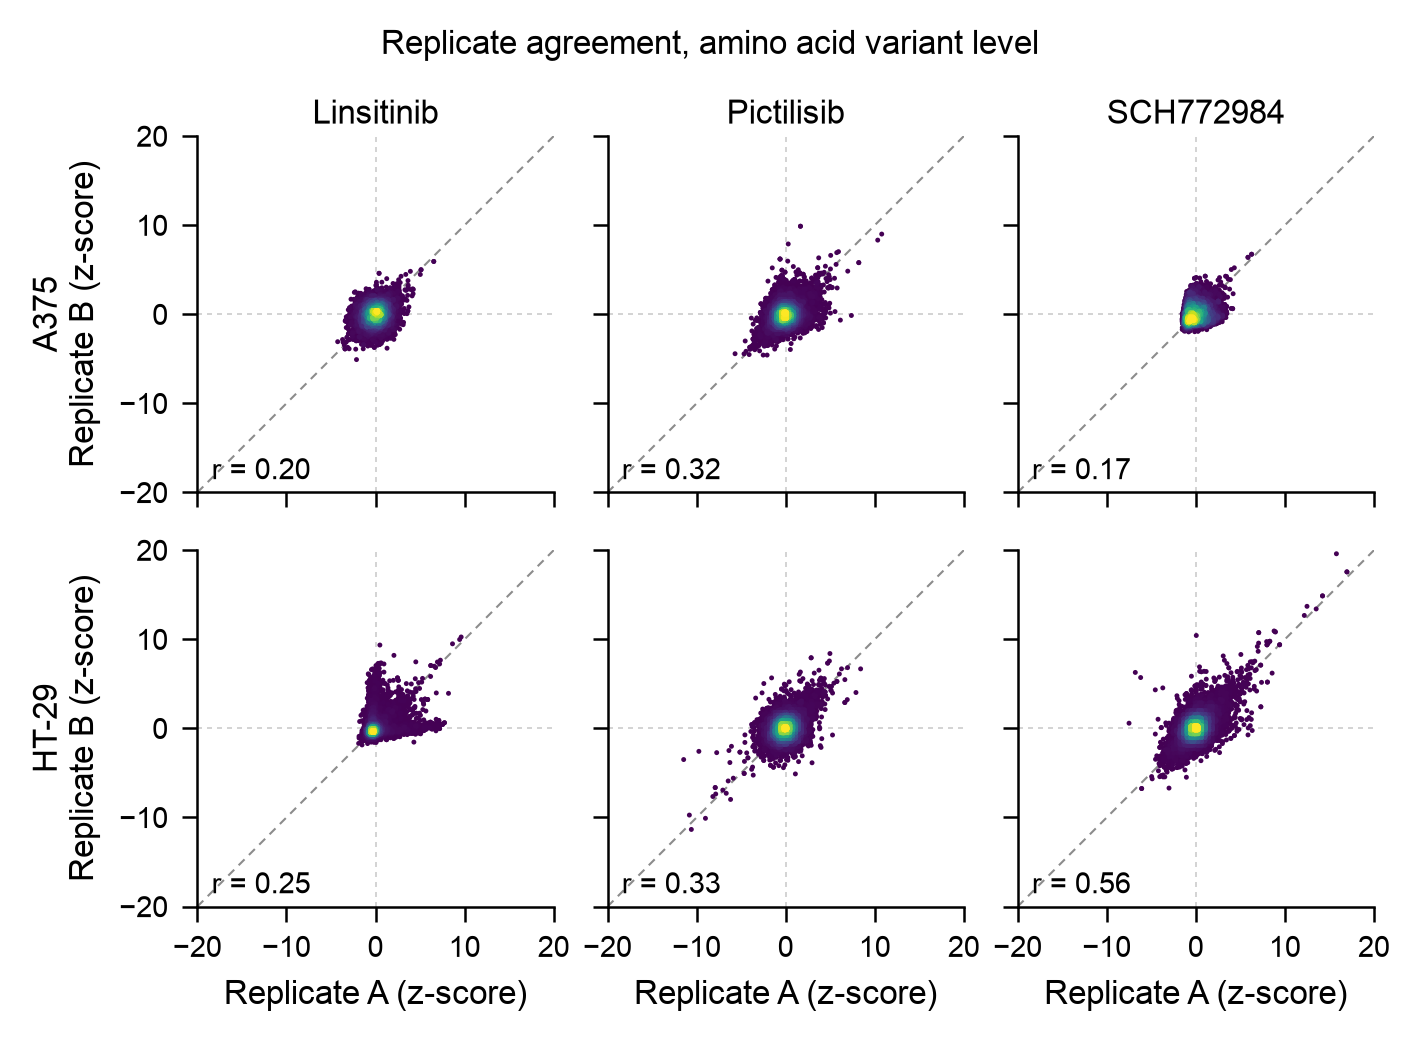

In [10]:
spread = variant_replicates.to_numpy()
reach = np.nanmax(np.abs(spread))
TICKS = axis_ticks(-reach, reach)

fig, axes = plt.subplots(2, 3, figsize=(4.6, 3.3), sharex=True, sharey=True)

for row, cell_line in enumerate(C.CELL_LINES):
    for column, arm in enumerate(C.DRUG_ARMS):
        ax = axes[row, column]
        rep_a = replicate_columns[(cell_line, arm, "A")]
        rep_b = replicate_columns[(cell_line, arm, "B")]
        pair = variant_replicates[[rep_a, rep_b]].dropna()
        x, y = pair[rep_a].to_numpy(), pair[rep_b].to_numpy()

        counts, xedges, yedges = np.histogram2d(x, y, bins=60)
        ix = np.clip(np.digitize(x, xedges[1:-1]), 0, 59)
        iy = np.clip(np.digitize(y, yedges[1:-1]), 0, 59)
        density = counts[ix, iy]
        order = density.argsort()
        ax.scatter(
            x[order], y[order], c=density[order], cmap="viridis",
            s=1.4, linewidths=0, rasterized=True,
        )

        ax.plot([TICKS[0], TICKS[-1]], [TICKS[0], TICKS[-1]], **DIAGONAL)
        ax.axhline(0, **ORIGIN)
        ax.axvline(0, **ORIGIN)
        ax.set_xticks(TICKS)
        ax.set_yticks(TICKS)
        ax.set_xlim(TICKS[0], TICKS[-1])
        ax.set_ylim(TICKS[0], TICKS[-1])
        ax.set_aspect("equal")
        ax.annotate(
            f"r = {stats.pearsonr(x, y)[0]:.2f}",
            xy=(0.04, 0.02), xycoords="axes fraction",
            ha="left", va="bottom", fontsize=7,
        )
        if row == 0:
            ax.set_title(C.ARM_LABEL[arm], fontsize=8, pad=3)
        if column == 0:
            ax.set_ylabel(f"{C.CELL_LINE_LABEL[cell_line]}\nReplicate B (z-score)")
        if row == len(C.CELL_LINES) - 1:
            ax.set_xlabel("Replicate A (z-score)")

fig.suptitle("Replicate agreement, amino acid variant level", fontsize=8, y=1.01)
fig.tight_layout(pad=0.3, w_pad=0.4, h_pad=0.4)
save_plot(fig, "qc_replicate_drug_vs_untreated_variants")
plt.show()

## Panels written


In [12]:
for path in sorted(C.PLOTS.glob("variant_*.png")) + sorted(
    C.PLOTS.glob("qc_replicate_drug_vs_untreated_variants.png")
):
    print(f"{path.name:52s} {path.stat().st_size / 1024:6.0f} KB")

variant_cell_lines_LIN.png                              305 KB
variant_cell_lines_PIC.png                              299 KB
variant_cell_lines_SCH.png                              260 KB
variant_position_DO_PIK3CA.png                          271 KB
variant_position_LIN_PIK3CA.png                         275 KB
variant_position_PIC_MTOR.png                           467 KB
variant_position_PIC_PGD.png                            277 KB
variant_position_PIC_PIK3CA.png                         304 KB
variant_position_PIC_PKM.png                            317 KB
variant_position_SCH_MAPK1.png                          217 KB
variant_position_SCH_MAPK3.png                          230 KB
variant_position_SCH_PIK3CA.png                         340 KB
qc_replicate_drug_vs_untreated_variants.png             376 KB
